# **UZPR – SEMESTRÁLNÍ PRÁCE**

**Název:** Analýza dopravních nehod v Brně

**Zpracovali:** Hnízdilová E., Zeman V. 

**Popis:**
* Projekt se bude zaměřovat na analýzu dopravních nehod na území statutárního města Brna s využitím dat o jednotlivých událostech, jejich příčinách, okolnostech a následcích. 

- Cílem projektu je získat komplexní přehled o dopravních nehodách, zejména o tom, kdy k nim dochází a jaké faktory je ovlivňují.

+ Analýza bude zahrnovat časové a prostorové rozložení nehod a dále vliv vybraných faktorů, jako jsou povětrnostní podmínky, viditelnost, přítomnost alkoholu či chování účastníků silničního provozu.

**Cíle projektu:**

* Prozkoumat časovou distribuci dopravních nehod a zjistit období s nejvyšším výskytem (denní doba, den v týdnu, měsíc, rok).
- Analyzovat prostorové rozložení nehod a identifikovat oblasti s nejvyšší četností.
+ Určit hlavní příčiny nehod a vyhodnotit jejich podíl na celkovém počtu událostí.


## **1. Načtení knihoven pro fungování projektu:**
- Import použitých knihoven v semestrální práci.

In [1]:
import pandas as pd                   # načtení csv
import geopandas as gpd               # práce s mapami a geografickými daty
import matplotlib.pyplot as plt       # vykreslování základních grafů
import matplotlib.patches as mpatches # tvorba grafických prvků pro legendy
import sys                            # přístup k systémovým funkcím (např. ukončení programu).
import zipfile                        # zip
import os                             # na kontrolu souborů
import numpy as np                    # numerické operace s poli a maticemi.
import folium                         # pro tvorbu interaktivních webových map (vizualizace bodů nehod)
from pyproj import CRS, Transformer   # pro práci se souřadnicovými systémy (např. konverze JTSK na WGS84)
from IPython.display import display   # pro správné zobrazení interaktivních prvků (např. Folium mapy) 
import requests                       # pro práci s webovými stránkami a API
from tqdm import tqdm                 # k jednoduchému zobrazení rychlých a přehledných progress barů 
import io                             # pro práci s daty uloženými v paměti místo v souborech
# import calendar                       # pro vytvoření nzvů dnů a měsíců automaticky
# import locale                         # čeština pro názvy dnů a měsíců
import folium.plugins as plugins      # pokročilé funkce pro interaktivní mapu
from shapely.geometry import Point    # k vytvoření a reprezentaci bodových geometrických objektů
from io import StringIO               # slouží k práci s textovými daty v paměti
from matplotlib.ticker import FuncFormatter # umožňuje vlastní formátování popisků os v grafech
import plotly.graph_objects as go     # poskytuje nástroje pro tvorbu interaktivních grafů a vizualizací
import warnings                       # slouží ke správě a potlačení varovných hlášení během běhu programu
import json                           # říká mi: vezmi tenhle velký balík dat a vytáhni z něj jen ty tvary

## **2. Následné nahrání všech potřebných dat pro zpracování:**
- V následující kapitole se importují použitá data.

### 2.1. Načtení dat dopravních nehod v Brně
- Automaticky se stahuje.
- Data obsahují informace o dopravních nehodách v Brně.

In [2]:
data_url = 'https://data.brno.cz/datasets/298c37feb1064873abdccdc2a10b605f_0.csv'

response = requests.get(data_url, stream=True)
total_size_in_bytes = int(response.headers.get('content-length', 0))

bytes_data = io.BytesIO()

print("Stahování dat může chvíli trvat, sledujte prosím ukazatel průběhu...")

with tqdm(total=total_size_in_bytes, unit='B', unit_scale=True, desc='Stahování CSV - dopravní nehody v Brně') as progress_bar:
    for chunk in response.iter_content(chunk_size=8192):
        if chunk: 
            bytes_data.write(chunk)
            progress_bar.update(len(chunk))
            
bytes_data.seek(0)

data = pd.read_csv(
    bytes_data,
    encoding='utf-8',
    sep=',',
    low_memory=False
)

print("\nStažení úspěšně dokončeno.")
display(data)

Stahování dat může chvíli trvat, sledujte prosím ukazatel průběhu...


Stahování CSV - dopravní nehody v Brně: 100%|██████████| 62.9M/62.9M [00:05<00:00, 10.7MB/s]



Stažení úspěšně dokončeno.


,OBJECTID,zuj,alkohol_vinik,hlavni_pricina,srazka,nasledky,pricina,stav_vozovky,povetrnostni_podm,rozhled,...,mesic,e,d,id_nehody,datum,hmotna_skoda,skoda_vozidlo,GlobalID,x,y
0,1,Brno-Bosonohy,ne,nesprávný způsob jízdy,srážka s jedoucím nekolejovým vozidlem,nehoda s následky na životě nebo zdraví,nedodržení bezpečné vzdálenosti za vozidlem,"povrch suchý, neznečistěný",jiné ztížené,dobré,...,10,-1162828.000,-604429.000,60023000061,10/13/2023 12:00:00 AM,146000,30000,c62eb690-ecc9-4d0d-b849-403c70c60d66,-604429.000,-1162828.000
1,2,Brno-Bosonohy,ne,nesprávný způsob jízdy,srážka s jedoucím nekolejovým vozidlem,nehoda s následky na životě nebo zdraví,nedodržení bezpečné vzdálenosti za vozidlem,"povrch suchý, neznečistěný",jiné ztížené,dobré,...,10,-1162828.000,-604429.000,60023000061,10/13/2023 12:00:00 AM,146000,30000,c2c5fdc8-598d-4d99-b843-571ad873baaa,-604429.000,-1162828.000
2,3,Brno-Bosonohy,ne,nesprávný způsob jízdy,srážka s jedoucím nekolejovým vozidlem,nehoda s následky na životě nebo zdraví,nedodržení bezpečné vzdálenosti za vozidlem,"povrch suchý, neznečistěný",jiné ztížené,dobré,...,10,-1162828.000,-604429.000,60023000061,10/13/2023 12:00:00 AM,146000,30000,0ed785d7-9fe2-4439-b7bf-761caf5d39bb,-604429.000,-1162828.000
3,4,Brno-Bosonohy,ne,nesprávný způsob jízdy,srážka s jedoucím nekolejovým vozidlem,nehoda s následky na životě nebo zdraví,nedodržení bezpečné vzdálenosti za vozidlem,"povrch suchý, neznečistěný",jiné ztížené,dobré,...,10,-1162828.000,-604429.000,60023000061,10/13/2023 12:00:00 AM,146000,30000,396ab3e3-1b85-4d51-8103-6c7ac2bec807,-604429.000,-1162828.000
4,5,Brno-střed,ne,nesprávný způsob jízdy,srážka s jedoucím nekolejovým vozidlem,nehoda s následky na životě nebo zdraví,řidič se plně nevěnoval řízení vozidla,"povrch suchý, neznečistěný",neztížené,dobré,...,1,-1160611.000,-599755.000,60223000001,1/1/2023 12:00:00 AM,32000,2000,e8500cfe-66c1-4f39-8e67-6657b06d50fb,-599755.000,-1160611.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74094,74103,Brno-Nový Lískovec,nezjišťováno,nedání přenosti v jízdě,srážka s chodcem,nehoda s následky na životě nebo zdraví,chodci na vyznačeném přechodu,povrch mokrý,neztížené,dobré,...,12,-1161863.000,-601620.000,60225229075,12/15/2022 12:00:00 AM,0,0,90842740-7ba1-46ee-a307-18eb79344803,-601620.000,-1161863.000
74095,74104,Brno-Řečkovice a Mokrá Hora,ne,nesprávný způsob jízdy,srážka s chodcem,nehoda s následky na životě nebo zdraví,řidič se plně nevěnoval řízení vozidla,povrch mokrý,mlha,dobré,...,12,-1156027.000,-599213.000,60226222123,12/22/2022 12:00:00 AM,0,0,60860707-7252-4af8-860f-0811af57e7c9,-599213.000,-1156027.000
74096,74105,Brno-Řečkovice a Mokrá Hora,ne,nesprávný způsob jízdy,srážka s chodcem,nehoda s následky na životě nebo zdraví,řidič se plně nevěnoval řízení vozidla,povrch mokrý,mlha,dobré,...,12,-1156027.000,-599213.000,60226222123,12/22/2022 12:00:00 AM,0,0,f58624dc-2557-4676-872a-0498a4805da7,-599213.000,-1156027.000
74097,74106,Brno-Chrlice,ano,nesprávný způsob jízdy,srážka s chodcem,nehoda s následky na životě nebo zdraví,nezvládnutí řízení vozidla,povrch mokrý,neztížené,dobré,...,12,-1167758.000,-595544.000,60226224381,12/29/2022 12:00:00 AM,80000,50000,a25a40ce-2b31-49a3-b8fa-4ddbfc930735,-595544.000,-1167758.000


### 2.2. Načtení dat o počtu obyvatel v městských částech Brna
- Bohužel nám nefunguje automatické stahování ze stránky: https://mv.gov.cz/soubor/cr-pocet-obyvatel-k-1-1-2025-xlsx.aspx. 
- Data obsahují názvy čtvrtí a počty obyvatel k 1.1.2025.
- Použitá data pokrývají celou ČR a byla manuálně upravena pro oblast Brna.

In [3]:
obyvatele = pd.read_csv('List 1.csv', header=None) # https://data.brno.cz/pages/bvc-obyvatelstvo-a-bydleni k 1.1.2025

obyvatele = obyvatele.rename(columns={0: 'Mestska_cast', 1: 'pocet_obyvatel'})
cast_obyv = obyvatele[['Mestska_cast', 'pocet_obyvatel']].copy()

cast_obyv['Mestska_cast'] = cast_obyv['Mestska_cast'].astype(str).str.strip('" ')
cast_obyv['pocet_obyvatel'] = cast_obyv['pocet_obyvatel'].astype(str).str.strip('" ')

cast_obyv['pocet_obyvatel'] = cast_obyv['pocet_obyvatel'].str.replace(' ', '', regex=False).str.replace(',', '', regex=False)
cast_obyv['pocet_obyvatel'] = pd.to_numeric(cast_obyv['pocet_obyvatel'], errors='coerce').astype('Int64')

cast_obyv = cast_obyv.dropna(subset=['pocet_obyvatel']).reset_index(drop=True)

display(cast_obyv)

,Mestska_cast,pocet_obyvatel
0,Brno-Bohunice,11961
1,Brno-Bosonohy,2422
2,Brno-Bystrc,22685
3,Brno-Černovice,6692
4,Brno-Chrlice,3121
5,Brno-Ivanovice,1869
6,Brno-Jehnice,1112
7,Brno-jih,7594
8,Brno-Jundrov,4379
9,Brno-Kníničky,1066


### 2.3. Načtení shapefile s městskými částmi Brna
- Automatické stahování ze stránky: https://data.brno.cz/datasets/1fcc06f548c34e93b9dd3014f8e58f8e_0/about.
- Data obsahují polygony městských částí k 2021.

In [4]:
data_url = 'https://data.brno.cz/datasets/1fcc06f548c34e93b9dd3014f8e58f8e_0.geojson'

response = requests.get(data_url, stream=True)
total_size = int(response.headers.get('content-length', 0))

bytes_data = io.BytesIO()

print("Stahování dat může chvíli trvat, sledujte prosím ukazatel průběhu...")

with tqdm(total=total_size if total_size > 0 else None, 
          unit='B', 
          unit_scale=True, 
          desc='Probíhá stahování',
          mininterval=0.1) as progress_bar:
    
    for chunk in response.iter_content(chunk_size=4096): 
        if chunk: 
            bytes_data.write(chunk)
            progress_bar.update(len(chunk))

bytes_data.seek(0)
json_str = bytes_data.read().decode('utf-8')
data_json = json.loads(json_str)

gdf_brno = gpd.GeoDataFrame.from_features(data_json["features"])

print("\nStažení úspěšně dokončeno.")
display(gdf_brno)

Stahování dat může chvíli trvat, sledujte prosím ukazatel průběhu...


Probíhá stahování: 100%|██████████| 1.05M/1.05M [00:00<00:00, 2.05MB/s]


Stažení úspěšně dokončeno.


,geometry,kod,nazev,datum_exportu,ObjectId,GlobalID
0,"POLYGON ((1848094.994 6324260.021, 1848111.614...",551422,Brno-Ořešín,"Thu, 18 Dec 2025 00:00:00 GMT",1,262423b1-16a7-4ffa-9b8d-f3bf229a597b
1,"POLYGON ((1860007.549 6315789.096, 1860050.997...",551287,Brno-Líšeň,"Thu, 18 Dec 2025 00:00:00 GMT",2,017eb430-7f99-4954-9691-2c6876b53456
2,"POLYGON ((1852516.95 6299218.182, 1852521.336 ...",551317,Brno-Chrlice,"Thu, 18 Dec 2025 00:00:00 GMT",3,dec44dfe-b027-48ee-9a2c-923136cb6e08
3,"POLYGON ((1851045.629 6307391.513, 1851051.484...",551066,Brno-Černovice,"Thu, 18 Dec 2025 00:00:00 GMT",4,c3b14c4e-1f55-46d1-9704-d86ec6994304
4,"POLYGON ((1841488.216 6318389.552, 1841492.569...",551236,Brno-Medlánky,"Thu, 18 Dec 2025 00:00:00 GMT",5,dd08102b-5a6b-4700-8187-fa27c804caaa
5,"POLYGON ((1856532.867 6311952.259, 1856565.45 ...",551279,Brno-Vinohrady,"Thu, 18 Dec 2025 00:00:00 GMT",6,61e7171d-7ba8-4af3-84c8-3dfa4ba434ab
6,"POLYGON ((1856557.413 6307672.059, 1856578.753...",551295,Brno-Slatina,"Thu, 18 Dec 2025 00:00:00 GMT",7,86ef2f24-3424-4d5e-8a2a-705dcb9d8a31
7,"POLYGON ((1845355.01 6321581.978, 1845358.427 ...",551376,Brno-Ivanovice,"Thu, 18 Dec 2025 00:00:00 GMT",8,7990981d-ff89-438b-a30f-d7faca078275
8,"POLYGON ((1851102.791 6324313.494, 1851096.391...",551431,Brno-Útěchov,"Thu, 18 Dec 2025 00:00:00 GMT",9,808b94af-4922-42b3-964d-7e839a0bedb2
9,"POLYGON ((1843807.803 6304931.562, 1843819.113...",551091,Brno-Starý Lískovec,"Thu, 18 Dec 2025 00:00:00 GMT",10,6e642437-26e8-496f-b4a7-af84d612d52f


### 2.4. Načtení dat základních škol
- CSV se automaticky stahuje: https://data.brno.cz/datasets/fa7d13f5ad064ddc8c714a825c4e32c5_0
- GeoJSONsoubor se automaticky stahuje: https://data.brno.cz/datasets/mestobrno::z%C3%A1kladn%C3%AD-%C5%A1koly-seznam-primary-schools-list/about
- Data obsahují informace o základních školách v Brně k 2021.

In [5]:
zakladky = 'https://data.brno.cz/datasets/fa7d13f5ad064ddc8c714a825c4e32c5_0.csv'

df_zakladky = pd.read_csv(
    zakladky, 
    encoding='utf-8', 
    sep=','
)

# Definice nových sloupců a jejich přejmenování
new_columns = {
    'cislo_orientacni_cislo': 'Č. orientační',
    'cislo_domovni': 'Č. domovní',
    'adrp_psc': 'PSČ',
    'ulice_nazev': 'Ulice',
    'naz_cobce': 'MČ (Část města)',
    'zs': 'Adresa (zkráceně)',
    'kod': 'Kód školy',
    'nazev_cely': 'Název školy (celý)'
}

df_zakladky = df_zakladky[list(new_columns.keys())]
df_zakladky = df_zakladky.rename(columns=new_columns)

display(df_zakladky)

,Č. orientační,Č. domovní,PSČ,Ulice,MČ (Část města),Adresa (zkráceně),Kód školy,Název školy (celý)
0,8,8,63900,Bakalovo nábřeží,Štýřice,Bakalovo nábřeží 8,2232,Základní škola
1,21,99,60200,Křenová,Trnitá,Křenová 21,2256,Základní škola a mateřská škola
2,2,577,61300,Janouškova,Černá Pole,Janouškova 2,2248,Základní škola Brno
3,23,4164,62800,Mutěnická,Židenice,Mutěnická 23,2229,Základní škola
4,24,3191,63600,Krásného,Židenice,Krásného 24,2254,Základní škola
...,...,...,...,...,...,...,...,...
59,7,2571,61600,náměstí Svornosti,Žabovřesky,nám. Svornosti 7,2268,"Základní a Mateřská škola Brno, náměstí Svorno..."
60,22,1902,60200,náměstí 28. října,Černá Pole,nám. 28. října 22,2279,Základní škola a mateřská škola
61,16,576,62300,Pavlovská,Kohoutovice,Pavlovská 16,2220,Základní a mateřská škola Brno
62,44,100,64200,Bosonožské náměstí,Bosonohy,Bosonožské nám. 44 (1.–5. ročník),2203,"Základní škola a Mateřská škola Brno, Bosonožs..."


In [6]:
data_url = 'https://data.brno.cz/datasets/mestobrno::z%C3%A1kladn%C3%AD-%C5%A1koly-seznam-primary-schools-list.geojson'

response = requests.get(data_url, stream=True)
total_size = int(response.headers.get('content-length', 0))

bytes_data = io.BytesIO()

print("Stahování dat může chvíli trvat, sledujte prosím ukazatel průběhu...")

with tqdm(total=total_size if total_size > 0 else None, 
          unit='B', 
          unit_scale=True, 
          desc='Probíhá stahování',
          mininterval=0.1) as progress_bar:
    
    for chunk in response.iter_content(chunk_size=4096): 
        if chunk: 
            bytes_data.write(chunk)
            progress_bar.update(len(chunk))

bytes_data.seek(0)
json_str = bytes_data.read().decode('utf-8')
data_json = json.loads(json_str)

ZIP_SKOLY = gpd.GeoDataFrame.from_features(data_json["features"])
ZIP_SKOLY.set_crs(epsg=4326, inplace=True)

print("\nStažení úspěšně dokončeno.")
display(ZIP_SKOLY)

Stahování dat může chvíli trvat, sledujte prosím ukazatel průběhu...


Probíhá stahování: 100%|██████████| 29.6k/29.6k [00:00<00:00, 74.1MB/s]


Stažení úspěšně dokončeno.


,geometry,objectid,cislo_orientacni_cislo,cislo_orientacni_hodnota,cislo_domovni,adrp_psc,ulice_nazev,naz_cobce,zs,kod,nazev_cely,datum_exportu,GlobalID
0,POINT (1847770.25321 6306302.87419),1,8,,8,63900,Bakalovo nábřeží,Štýřice,Bakalovo nábřeží 8,2232,Základní škola,"Fri, 19 Dec 2025 00:00:00 GMT",b1e7086e-4b6a-417a-b925-e546e0a2add7
1,POINT (1850053.23786 6307540.89794),2,21,,99,60200,Křenová,Trnitá,Křenová 21,2256,Základní škola a mateřská škola,"Fri, 19 Dec 2025 00:00:00 GMT",7f777359-79de-4448-b9cb-6d24d181dab7
2,POINT (1850368.87314 6312245.9094),3,2,,577,61300,Janouškova,Černá Pole,Janouškova 2,2248,Základní škola Brno,"Fri, 19 Dec 2025 00:00:00 GMT",77cc0538-5afb-4334-999d-8c8e773c2421
3,POINT (1854681.90228 6309456.21942),4,23,,4164,62800,Mutěnická,Židenice,Mutěnická 23,2229,Základní škola,"Fri, 19 Dec 2025 00:00:00 GMT",69adaa16-2566-4651-8486-be06bbede3e8
4,POINT (1854110.2433 6307175.77052),5,24,,3191,63600,Krásného,Židenice,Krásného 24,2254,Základní škola,"Fri, 19 Dec 2025 00:00:00 GMT",935997a7-5760-42e5-807c-7e36d79274a6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,POINT (1845727.70753 6311481.23012),60,7,,2571,61600,náměstí Svornosti,Žabovřesky,nám. Svornosti 7,2268,"Základní a Mateřská škola Brno, náměstí Svorno...","Fri, 19 Dec 2025 00:00:00 GMT",3220ff7a-4663-4cfe-84f2-7529da7c6b24
60,POINT (1849458.37989 6309271.63591),61,22,,1902,60200,náměstí 28. října,Černá Pole,nám. 28. října 22,2279,Základní škola a mateřská škola,"Fri, 19 Dec 2025 00:00:00 GMT",be028587-afca-4c66-a0ee-fb69c90d1ede
61,POINT (1839881.63089 6307318.62755),62,16,,576,62300,Pavlovská,Kohoutovice,Pavlovská 16,2220,Základní a mateřská škola Brno,"Fri, 19 Dec 2025 00:00:00 GMT",0c8b986d-d924-4f48-aa00-2a88dad73aac
62,POINT (1840114.03259 6304762.48808),63,44,,100,64200,Bosonožské náměstí,Bosonohy,Bosonožské nám. 44 (1.–5. ročník),2203,"Základní škola a Mateřská škola Brno, Bosonožs...","Fri, 19 Dec 2025 00:00:00 GMT",c2f6adb1-aa86-43b4-b51b-227fea6f1f35


### 2.5. Načtení dat mateřských školek
- CSV se automaticky stahuje: https://data.brno.cz/datasets/df593d71d0a344838732bec65a7d84a4_0
- GeoJSON soubor se automaticky stahuje: https://data.brno.cz/datasets/mestobrno::mate%C5%99sk%C3%A9-%C5%A1koly-seznam-kindergartens-list
- Data obsahují informace o mateřských školkách v Brně k 2021.

In [7]:
skolky = 'https://data.brno.cz/datasets/df593d71d0a344838732bec65a7d84a4_0.csv'

df_skolky = pd.read_csv(
    skolky, 
    encoding='utf-8', 
    sep=','
)

column_skolky = {
    'cislo_domo': 'Č. domovní',
    'cislo_orie': 'Č. orientační',
    'mc': 'MČ (Část města)',
    'ulice_naze': 'Ulice',
    'kod': 'Kód školy',
    'adresa': 'Adresa (celá)'
}

df_skolky = df_skolky[list(column_skolky.keys())]
df_skolky = df_skolky.rename(columns=column_skolky)

display(df_skolky)

,Č. domovní,Č. orientační,MČ (Část města),Ulice,Kód školy,Adresa (celá)
0,743,4,BRNO-BOHUNICE,Amerlingova,2186,Amerlingova 4
1,1791,169,BRNO-SEVER,Tišnovská,2127,Tišnovská 169
2,645,55,BRNO-CHRLICE,Šromova,2014,Šromova 55
3,932,37,BRNO-SEVER,Merhautova,2264,Merhautova 37
4,388,3,BRNO-CHRLICE,Jana Broskvy,2262,Jana Broskvy 3
...,...,...,...,...,...,...
131,2170,1,BRNO-LÍŠEN,Horníkova,2233,Horníkova 1
132,109,70,BRNO-JIH,Zelná,2149,Zelná 70
133,1493,23,BRNO-BYSTRC,Nad dědinou,2077,Nad dědinou 23
134,576,16,BRNO-KOHOUTOVICE,Pavlovská,2001,Pavlovská 16


In [8]:
data_url = ' https://data.brno.cz/datasets/mestobrno::mate%C5%99sk%C3%A9-%C5%A1koly-seznam-kindergartens-list.geojson'

response = requests.get(data_url, stream=True)
total_size = int(response.headers.get('content-length', 0))

bytes_data = io.BytesIO()

print("Stahování dat může chvíli trvat, sledujte prosím ukazatel průběhu...")

with tqdm(total=total_size if total_size > 0 else None, 
          unit='B', 
          unit_scale=True, 
          desc='Probíhá stahování',
          mininterval=0.1) as progress_bar:
    
    for chunk in response.iter_content(chunk_size=4096): 
        if chunk: 
            bytes_data.write(chunk)
            progress_bar.update(len(chunk))

bytes_data.seek(0)
json_str = bytes_data.read().decode('utf-8')
data_json = json.loads(json_str)

ZIP_SKOLKY = gpd.GeoDataFrame.from_features(data_json["features"])
ZIP_SKOLKY.set_crs(epsg=4326, inplace=True)

print("\nStažení úspěšně dokončeno.")
display(ZIP_SKOLKY)

Stahování dat může chvíli trvat, sledujte prosím ukazatel průběhu...


Probíhá stahování: 100%|██████████| 55.3k/55.3k [00:00<00:00, 518kB/s]


Stažení úspěšně dokončeno.


,geometry,objectid_12,kod_ruian,cislo_domo,cislo_orie,cislo_or_1,mc,ulice_naze,kod,adresa,datum_exportu,ObjectId,GlobalID
0,POINT (1845501.61765 6303382.38608),1,25753193,743,4,,BRNO-BOHUNICE,Amerlingova,2186,Amerlingova 4,"Fri, 19 Dec 2025 00:00:00 GMT",1,94babdf1-e161-499d-a375-22eefa950f59
1,POINT (1851038.03686 6311294.57431),20,19306610,1791,169,,BRNO-SEVER,Tišnovská,2127,Tišnovská 169,"Fri, 19 Dec 2025 00:00:00 GMT",2,80a9060c-4416-432d-bc0a-1555d4f70613
2,POINT (1853784.90096 6296782.20229),21,19065400,645,55,,BRNO-CHRLICE,Šromova,2014,Šromova 55,"Fri, 19 Dec 2025 00:00:00 GMT",3,93484ab1-a5a0-41b8-b1c5-9ceedbd32c78
3,POINT (1850598.83694 6309751.60575),22,19297688,932,37,,BRNO-SEVER,Merhautova,2264,Merhautova 37,"Fri, 19 Dec 2025 00:00:00 GMT",4,1b5d8fa7-0116-4e5c-beb0-35e74a7934c8
4,POINT (1854088.42468 6297729.51878),24,19062737,388,3,,BRNO-CHRLICE,Jana Broskvy,2262,Jana Broskvy 3,"Fri, 19 Dec 2025 00:00:00 GMT",5,618dcad2-ebf2-44e7-ac78-7bb8eff10515
...,...,...,...,...,...,...,...,...,...,...,...,...,...
131,POINT (1856736.73763 6311080.45267),75,19433182,2170,1,,BRNO-LÍŠEN,Horníkova,2233,Horníkova 1,"Fri, 19 Dec 2025 00:00:00 GMT",132,17c1278e-09e6-4b58-8b6f-853662a3678b
132,POINT (1850360.00098 6300178.53629),76,19035942,109,70,,BRNO-JIH,Zelná,2149,Zelná 70,"Fri, 19 Dec 2025 00:00:00 GMT",133,e0c5d6e5-e362-4089-ae39-009f225646fd
133,POINT (1838751.88277 6312803.97533),139,85375039,1493,23,,BRNO-BYSTRC,Nad dědinou,2077,Nad dědinou 23,"Fri, 19 Dec 2025 00:00:00 GMT",134,a35d81c8-3d5e-4e4f-a923-79b6d1d7318b
134,POINT (1839877.5566 6307311.40544),137,19385099,576,16,,BRNO-KOHOUTOVICE,Pavlovská,2001,Pavlovská 16,"Fri, 19 Dec 2025 00:00:00 GMT",135,ca2b5115-0336-4776-8ea0-508362e7d823


## 3. Výstupní data
- Analýzy a výstupy jsou uvedeny v následující kapitole.

### 3.1. Mapa - městské části statutárního města Brna
- Skript vykresluje městské části Brna.

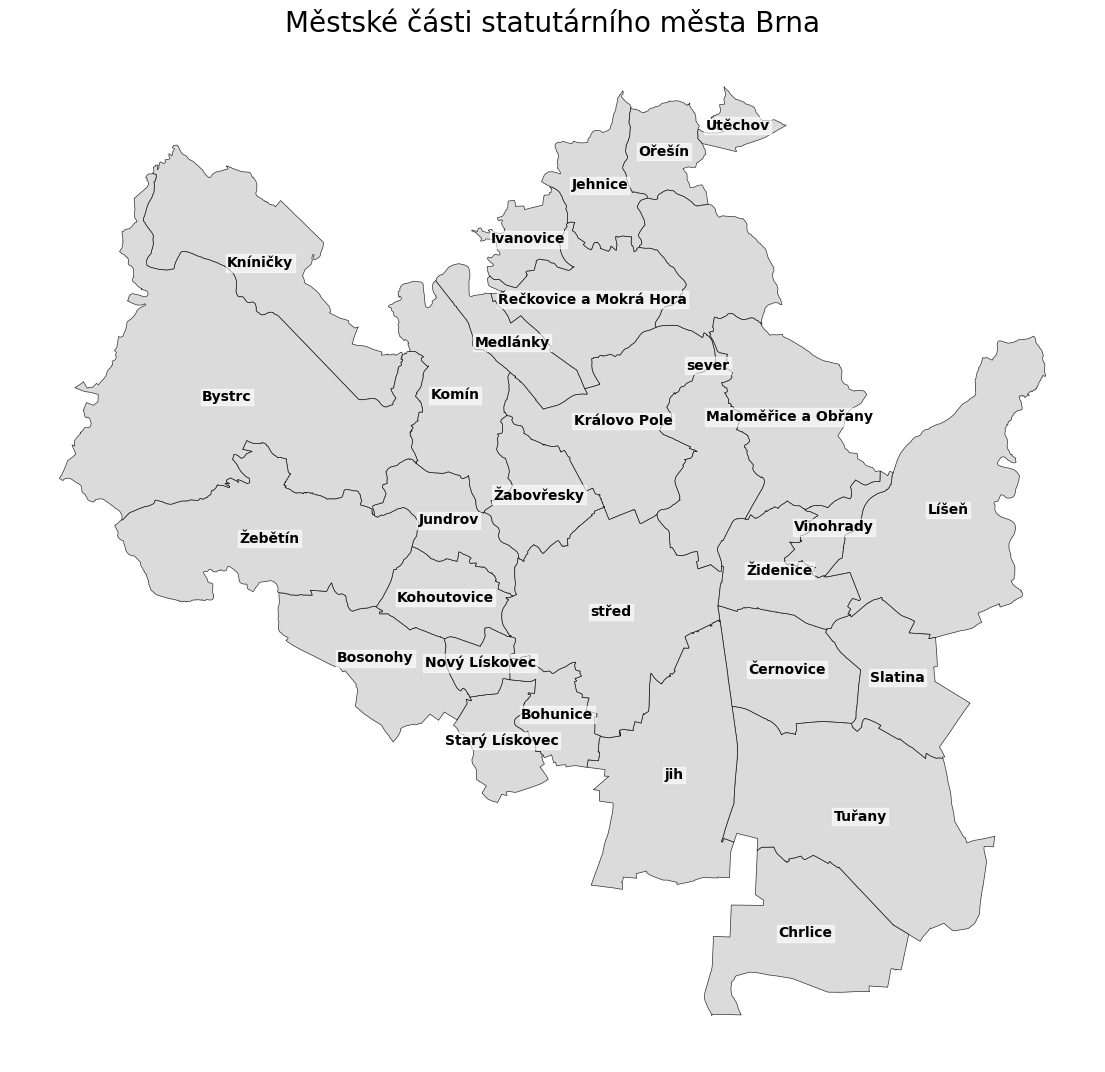

In [9]:
SLOUPEC_S_NAZVY = 'nazev'

fig, ax = plt.subplots(1, 1, figsize=(14, 14))
    
gdf_brno.plot(
    ax=ax,
    edgecolor='black',
    linewidth=0.5,
    color='lightgray',
    alpha=0.8
)
    
for idx, row in gdf_brno.iterrows():
    centroid = row.geometry.centroid
    nazev = row[SLOUPEC_S_NAZVY].replace('Brno-', '')
        
    ax.text(
        centroid.x,
        centroid.y,
        nazev, 
        fontsize=10,
        ha='center',
        va='center',
        color='black',
        weight='bold',
        wrap=True,
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='white', pad=1)
    )
plt.title('Městské části statutárního města Brna', fontsize=20)
ax.set_axis_off() 
plt.show()

### 3.2. Graf - počet dopravních nehod v jednotlivých měsících
- Graf zobrazuje četnost dopravních nehod v jednotlivých měsících.
- Rozdělení hodnot podle barev: červená (nad 66 %), oranžová (33–66 %) a světle modrá (pod 33 %).
- Názvy měsíců v češtině nelze automatizovaně generovat pomocí knihovny Calendar.

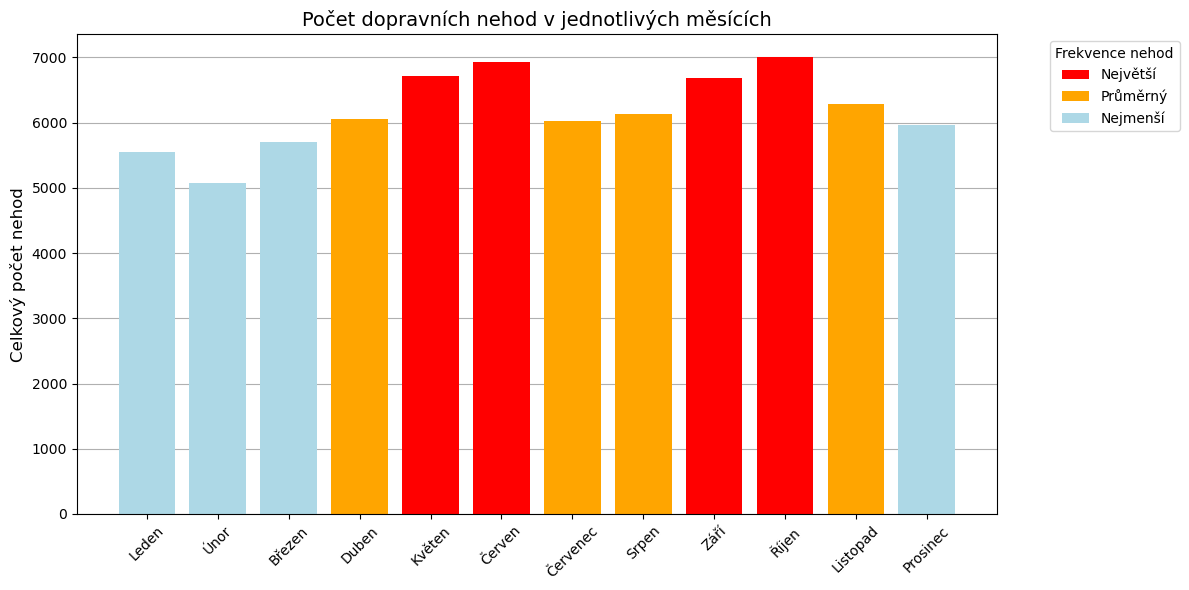

In [10]:
mesicni_nehody = data['mesic'].value_counts().sort_index()

nazvy_mesicu = ['Leden', 'Únor', 'Březen', 'Duben', 'Květen', 'Červen',
                'Červenec', 'Srpen', 'Září', 'Říjen', 'Listopad', 'Prosinec']

hranice_spodni = mesicni_nehody.quantile(0.33)
hranice_horni = mesicni_nehody.quantile(0.66)

barvy = []
for hodnota in mesicni_nehody.values:
    if hodnota > hranice_horni:
        barvy.append('red')
    elif hodnota < hranice_spodni:
        barvy.append('lightblue')
    else:
        barvy.append('orange')

plt.figure(figsize=(12, 6))
plt.bar(nazvy_mesicu, mesicni_nehody.values, color=barvy)
ax = plt.gca() 
ax.grid(axis='y', zorder=1)

for container in ax.containers:
    plt.setp(container, zorder=2)

plt.title('Počet dopravních nehod v jednotlivých měsících', fontsize=14)
plt.ylabel('Celkový počet nehod', fontsize=12)
plt.xticks(rotation=45)

legend_elements = [
    mpatches.Patch(facecolor='red', label='Největší'),
    mpatches.Patch(facecolor='orange', label='Průměrný'),
    mpatches.Patch(facecolor='lightblue', label='Nejmenší'),
]

plt.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.05, 1), title="Frekvence nehod")

plt.tight_layout()
plt.show()

### 3.3. Graf - Týdenní rozložení dopravních nehod
- Graf zobrazuje četnost dopravních nehod v týdenním rozložení.
- Rozdělení hodnot podle barev: červená (nad 66 %), oranžová (33–66 %) a světle zelená (pod 33 %).
- Názvy dnů v češtině nelze automatizovaně generovat pomocí knihovny Calendar.

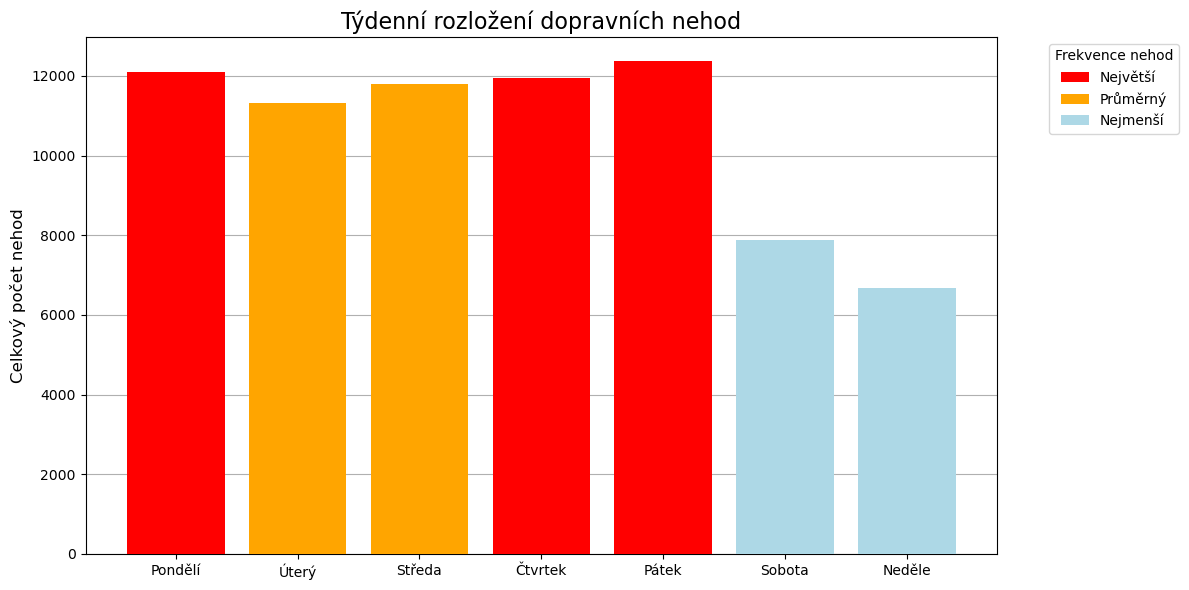

In [11]:
denni_nehody = data['den'].value_counts().sort_index()

nazvy_dnu = ['Pondělí', 'Úterý', 'Středa', 'Čtvrtek', 'Pátek', 'Sobota', 'Neděle']

hranice_spodni = denni_nehody.quantile(0.33)
hranice_horni = denni_nehody.quantile(0.66)

barvy = []
for hodnota in denni_nehody.values:
    if hodnota > hranice_horni:
        barvy.append('red')
    elif hodnota < hranice_spodni:
        barvy.append('lightblue')
    else:
        barvy.append('orange')

plt.figure(figsize=(12, 6))
plt.bar(nazvy_dnu, denni_nehody.values, color=barvy)
ax = plt.gca()
plt.title('Týdenní rozložení dopravních nehod', fontsize=16)
plt.ylabel('Celkový počet nehod', fontsize=12)
ax.grid(axis='y', zorder=1) 

for container in ax.containers:
    plt.setp(container, zorder=3)
    
legend_elements = [
    mpatches.Patch(facecolor='red', label='Největší'),
    mpatches.Patch(facecolor='orange', label='Průměrný'),
    mpatches.Patch(facecolor='lightblue', label='Nejmenší'),
]

plt.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.05, 1), title="Frekvence nehod")

plt.tight_layout()
plt.show()

### 3.4. Graf - četnost nehod v jednotlivých dnech měsíce
- Graf zobrazuje počet nehod v jednotlivých dnech měsíce.
- Rozdělení hodnot podle barev: červená (nad 66 %), oranžová (33–66 %) a světle modrá (pod 33 %).
- Pod grafem jsou uvedeny dny s nejmenším a největším počtem nehod a jejich četností.
- Pro zajímavost.


/tmp/ipykernel_1472181/3904433079.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data['datum'] = pd.to_datetime(data['datum'])# format='%m/%d/%Y')


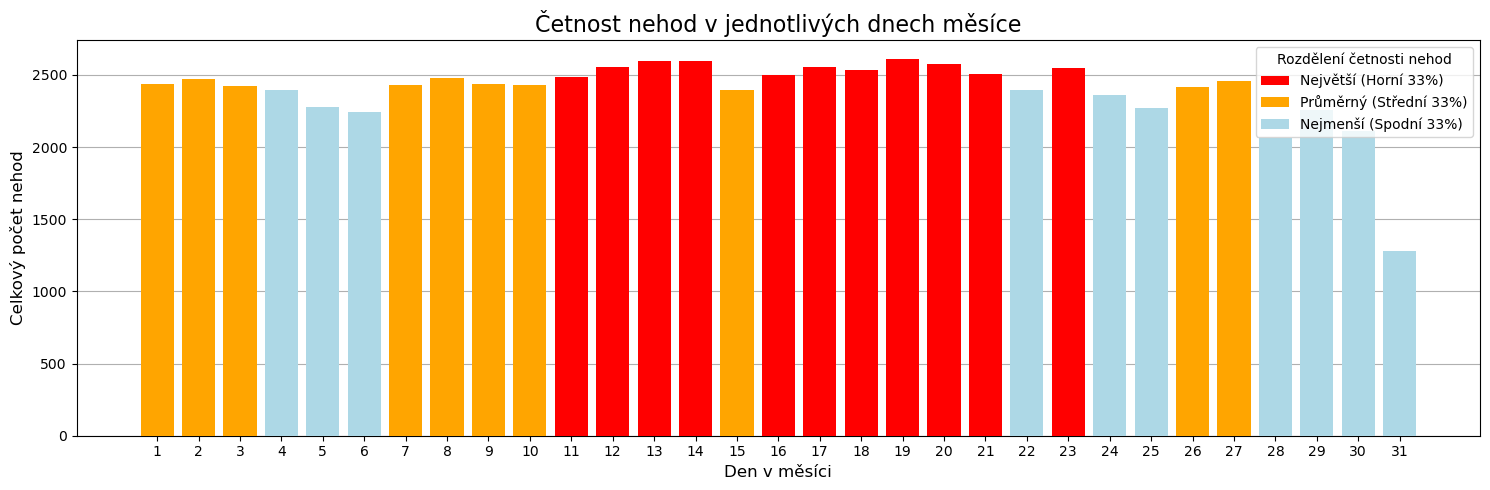

Nejrizikovějším dnem v měsíci je: 19. den (Četnost výskytu: 2609)
Nejméně rizikovým dnem v měsíci je: 31. den (Četnost výskytu: 1282)


In [12]:
if data['datum'].dtype != '<M8[ns]':
    # kontrola datumu 
   data['datum'] = pd.to_datetime(data['datum'])# format='%m/%d/%Y')
# Vytáhnutí dne v měsíci (číslo 1-31)
dny_v_mesici = data['datum'].dt.day.dropna()

# Spočítání četnosti nehod pro každý den v měsíci
cetnost_dnu = dny_v_mesici.value_counts().sort_index()

hranice_spodni = cetnost_dnu.quantile(0.33)
hranice_horni = cetnost_dnu.quantile(0.66)

barvy_sloupcu = []
for pocet in cetnost_dnu.values:
    if pocet > hranice_horni:
        barvy_sloupcu.append('red')       # Horní 33%
    elif pocet < hranice_spodni:
        barvy_sloupcu.append('lightblue') # Spodní 33%
    else:
        barvy_sloupcu.append('orange')    # Střední 33%

plt.figure(figsize=(15, 5))

plt.bar(cetnost_dnu.index, cetnost_dnu.values, color=barvy_sloupcu)
ax = plt.gca() 
ax.grid(axis='y', zorder=1)
for container in ax.containers:
    plt.setp(container, zorder=3)

plt.title('Četnost nehod v jednotlivých dnech měsíce', fontsize=16)
plt.xlabel('Den v měsíci', fontsize=12)
plt.ylabel('Celkový počet nehod', fontsize=12)
plt.xticks(cetnost_dnu.index) 

legend_elements = [
    mpatches.Patch(facecolor='red', label='Největší (Horní 33%)'),
    mpatches.Patch(facecolor='orange', label='Průměrný (Střední 33%)'),
    mpatches.Patch(facecolor='lightblue', label='Nejmenší (Spodní 33%)'),
]

plt.legend(handles=legend_elements, loc='upper right', title="Rozdělení četnosti nehod", frameon=True)

plt.tight_layout()
plt.show()

nejcastejsi_den = cetnost_dnu.idxmax()
pocet_vyskytu_max = cetnost_dnu.max()

nejmin_den = cetnost_dnu.idxmin()
pocet_vyskytu_min = cetnost_dnu.min()

print(f"Nejrizikovějším dnem v měsíci je: {nejcastejsi_den}. den (Četnost výskytu: {pocet_vyskytu_max})")
print(f"Nejméně rizikovým dnem v měsíci je: {nejmin_den}. den (Četnost výskytu: {pocet_vyskytu_min})")

### 3.5. Graf - rozdělení dopravních nehod podle příčiny
- Graf zobrazuje rozdělení dopravních nehod podle příčiny.

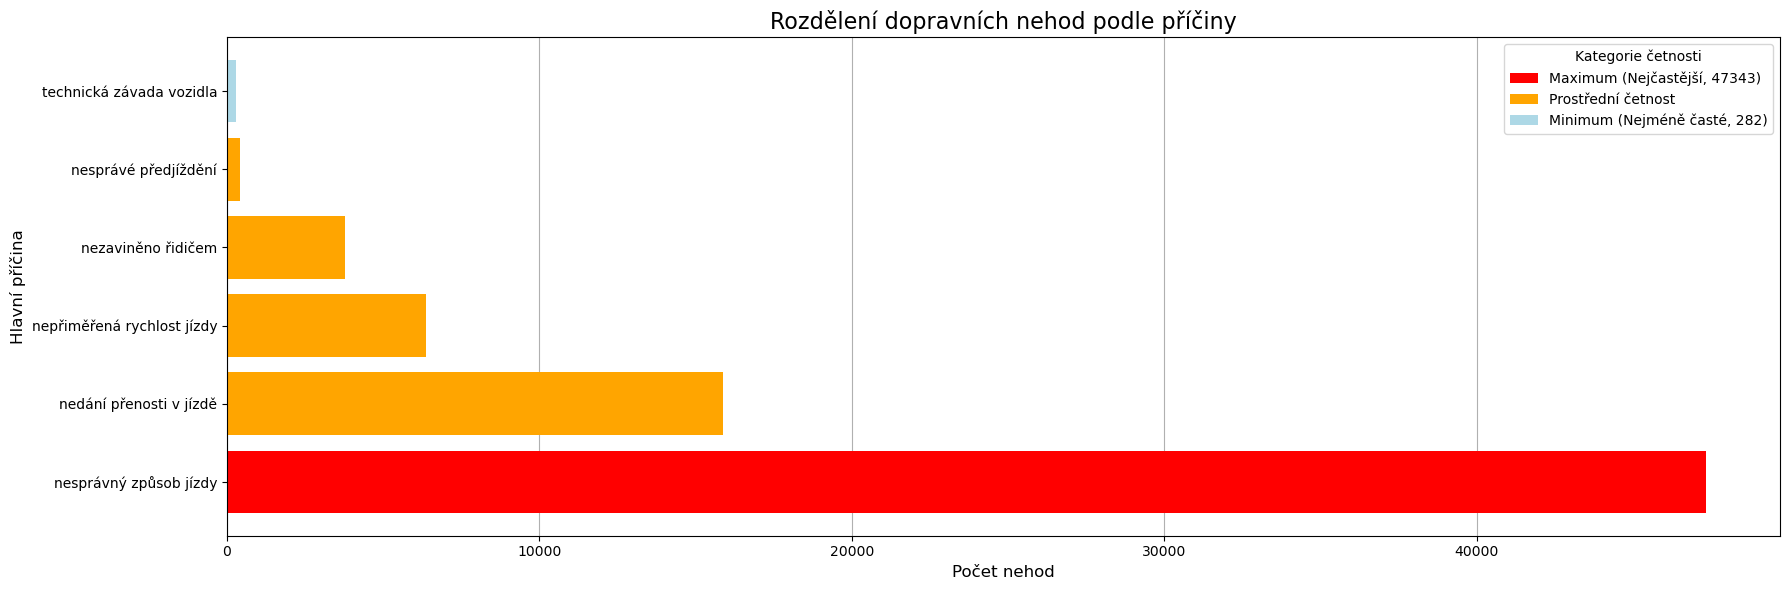

Nejčastější příčinou nehod je nesprávný způsob jízdy.


In [13]:
vsechny_priciny = data['hlavni_pricina'].value_counts()

# Zjištění extrémů pro barvení ze VŠECH PŘÍČIN 
pocet_max = vsechny_priciny.max()
pocet_min = vsechny_priciny.min()
    
barvy_sloupcu = [
    'red' if pocet == pocet_max else      # Červená pro maximum
    'lightblue' if pocet == pocet_min else  # Světle modrá pro minimum
    'orange'                             # Oranžová pro vše ostatní
    for pocet in vsechny_priciny.values
]
    
plt.figure(figsize=(18, 6))
plt.barh(vsechny_priciny.index, vsechny_priciny.values, color=barvy_sloupcu)
ax = plt.gca() 
ax.grid(axis='x', zorder=1)

for container in ax.containers:
    plt.setp(container, zorder=2)


plt.title('Rozdělení dopravních nehod podle příčiny', fontsize=16)
plt.xlabel('Počet nehod', fontsize=12)
plt.ylabel('Hlavní příčina', fontsize=12)


legend_elements = [
    mpatches.Patch(facecolor='red', label=f'Maximum (Nejčastější, {pocet_max})'),
    mpatches.Patch(facecolor='orange', label='Prostřední četnost'),
    mpatches.Patch(facecolor='lightblue', label=f'Minimum (Nejméně časté, {pocet_min})')
]

plt.legend(handles=legend_elements, loc='upper right', title="Kategorie četnosti", frameon=True)

plt.tight_layout()
plt.show()

print("Nejčastější příčinou nehod je nesprávný způsob jízdy.")

### 3.6. Graf - denní distribuce dopravních nehod podle hodin
- Graf zobrazuje rozdělení dopravních nehod podle hodin.
- Hodiny 0 a 24 byly sloučeny, jelikož představují stejný časový okamžik (půlnoc).

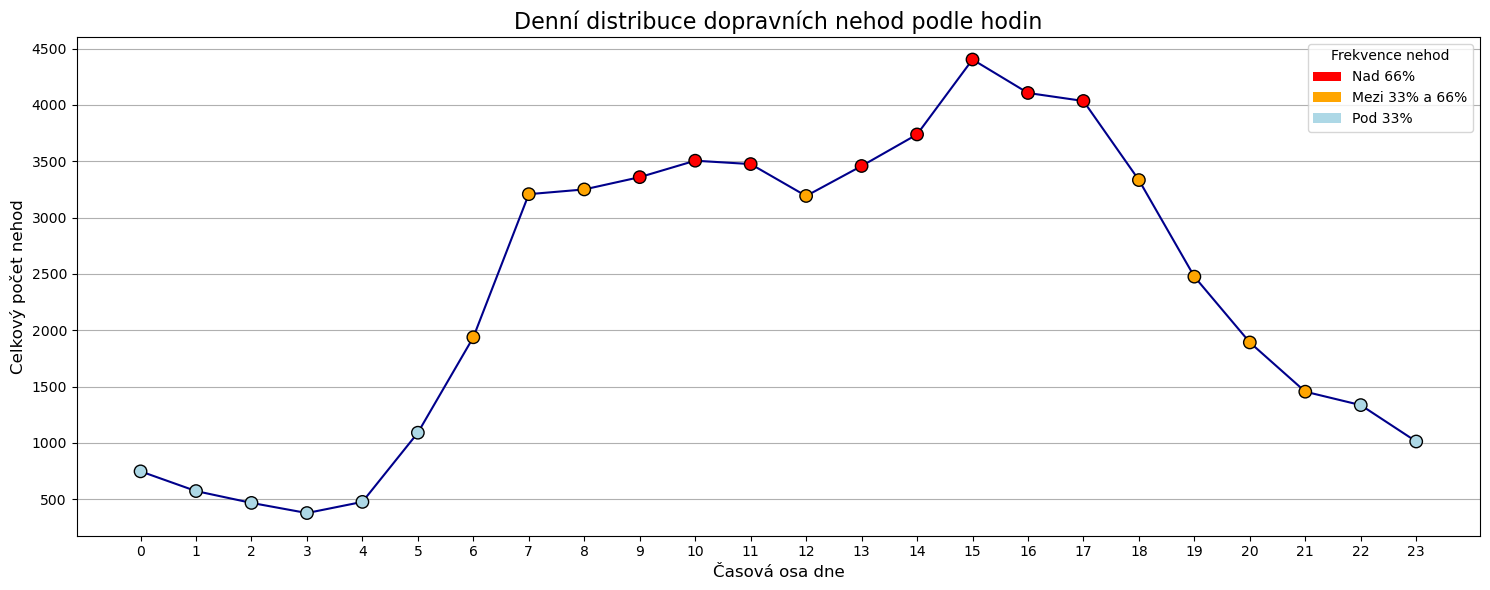

In [14]:
# Převedení sloupce 'hodina' na číselný typ
data['hodina'] = pd.to_numeric(data['hodina'], errors='coerce')

# Odstranění NaN hodnot, převedení na celá čísla a výpočet četností
nehody_dle_hodiny = data['hodina'].dropna().astype(int).value_counts().sort_index()

# Kontrola, zda máme skutečně jen 24 hodnot (0 až 23)
if len(nehody_dle_hodiny) != 24:
    nehody_dle_hodiny = nehody_dle_hodiny.reindex(range(24), fill_value=0)

X = nehody_dle_hodiny.index.to_numpy()
Y = nehody_dle_hodiny.values

hranice_spodni = np.quantile(Y, 0.33)
hranice_horni = np.quantile(Y, 0.66)

barvy_bodu = []
for hodnota in Y:
    if hodnota > hranice_horni:
        barvy_bodu.append('red')       
    elif hodnota < hranice_spodni:
        barvy_bodu.append('lightblue')  
    else:
        barvy_bodu.append('orange')     

plt.figure(figsize=(15, 6))
ax = plt.gca()

# Vykreslení spojnice (linie)
ax.plot(
    X, 
    Y, 
    linestyle='-', 
    color='darkblue', 
    label='Linie trendu',
    zorder=2
)

# Vykreslení bodů (scatter plot) s barvami
scatter = ax.scatter(
    X, 
    Y, 
    c=barvy_bodu,         
    marker='o', 
    s=80,                 
    edgecolor='black',    
    zorder=3
)

ax.grid(axis='y', zorder=1)
ax.set_xticks(range(24))

plt.title('Denní distribuce dopravních nehod podle hodin', fontsize=16)
plt.xlabel('Časová osa dne', fontsize=12)
plt.ylabel('Celkový počet nehod', fontsize=12)

legend_elements = [
    mpatches.Patch(facecolor='red', label=f'Nad 66%'),
    mpatches.Patch(facecolor='orange', label=f'Mezi 33% a 66%'),
    mpatches.Patch(facecolor='lightblue', label=f'Pod 33%')
]
ax.legend(handles=legend_elements, loc='upper right', title="Frekvence nehod")

plt.tight_layout()
plt.show()

### 3.7. Graf - Dopravní nehody za zhoršené viditelnosti podle denní doby
- Graf zobrazuje dopravní nehody za zhoršené viditelnosti v závislosti na denní době (den a noc).
- Z analýzy byly vynechány případy s dobrou viditelností za denního světla (tj. „ve dne, viditelnost nezhoršená vlivem povětrnostních podmínek“).

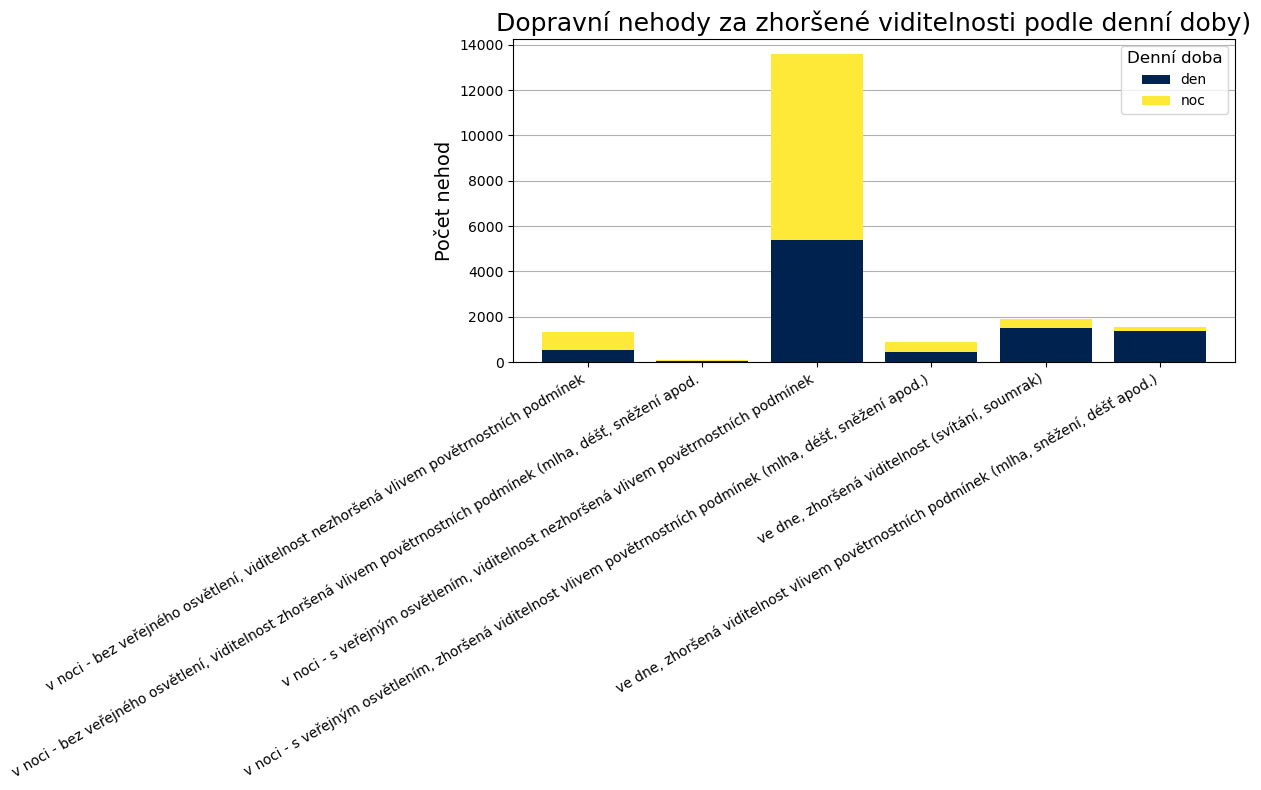

In [15]:
KATEGORIE_K_ODSTRANENI = 've dne, viditelnost nezhoršená vlivem povětrnostních podmínek'

data_filtrovana = data[data['viditelnost'] != KATEGORIE_K_ODSTRANENI].copy()

viditelnost_doba_cross = pd.crosstab(data_filtrovana['viditelnost'], data_filtrovana['doba'])

ax = viditelnost_doba_cross.plot(
    kind='bar', 
    stacked=True, 
    figsize=(12, 8), 
    colormap='cividis', 
    width=0.8
)

for container in ax.containers:
    plt.setp(container, zorder=3)

plt.title('Dopravní nehody za zhoršené viditelnosti podle denní doby', fontsize=18) 

plt.ylabel('Počet nehod', fontsize=14)
plt.xlabel('', fontsize=14)

plt.xticks(rotation=30, ha='right', fontsize=10)
plt.yticks(fontsize=10)

plt.legend(title='Denní doba', 
           title_fontsize=12,
           fontsize=10, 
           loc='upper right') 

ax.grid(axis='y', zorder=1)

plt.tight_layout()
plt.show()

### 3.8. Graf - 10 nejčastějších typů dopravních nehod
- Graf zobrazuje deset nejčastějších typů dopravních nehod v Brně.
- Název „srážka s tramvají“ byl upraven na „srážka se šalinou“, jelikož v Brně se běžně používá označení „šalina“.



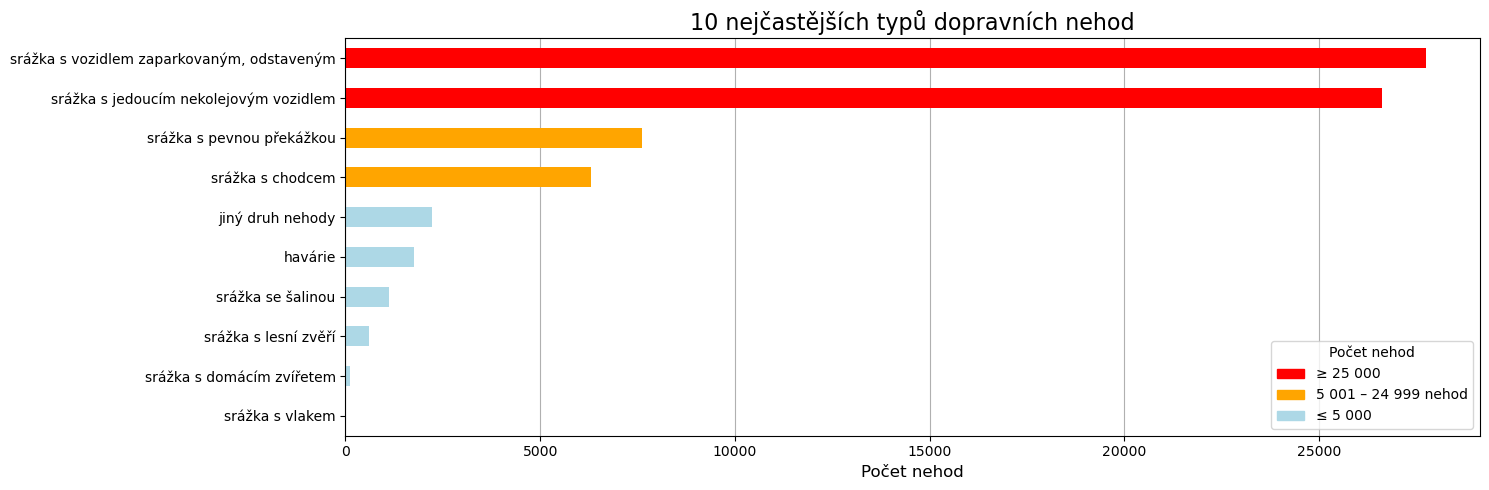

In [16]:
top_srazky = data['srazka'].value_counts().head(10).sort_values(ascending=True)

# Změna názvu "srážka s tramvají" na "srážka se šalinou"
top_srazky.index = top_srazky.index.str.replace(
    'srážka s tramvají',
    'srážka se šalinou'
)

barvy = [
    'red' if hodnota >= 25000 else 
    'orange' if hodnota >= 5000 else  
    'lightblue' 
    for hodnota in top_srazky.values
]

plt.figure(figsize=(15, 5))

ax = top_srazky.plot(kind='barh', color=barvy)

for container in ax.containers:
    plt.setp(container, zorder=2)
    
plt.title('10 nejčastějších typů dopravních nehod', fontsize=16)
ax.set_ylabel('', fontsize=12) 
plt.xlabel('Počet nehod', fontsize=12)

cervena = mpatches.Patch(color='red', label='≥ 25 000')
oranzova = mpatches.Patch(color='orange', label='5 001 – 24 999 nehod') 
svetla = mpatches.Patch(color='lightblue', label='≤ 5 000') 

plt.legend(
    handles=[cervena, oranzova, svetla], 
    title='Počet nehod', 
    loc='lower right'
)

ax.grid(axis='x', zorder=1)
plt.tight_layout()
plt.show()

### 3.9. Graf - počet dopravních nehod podle městských částí Brna
- Graf zobrazuje počet dopravních nehod v jednotlivých městských částech Brna.

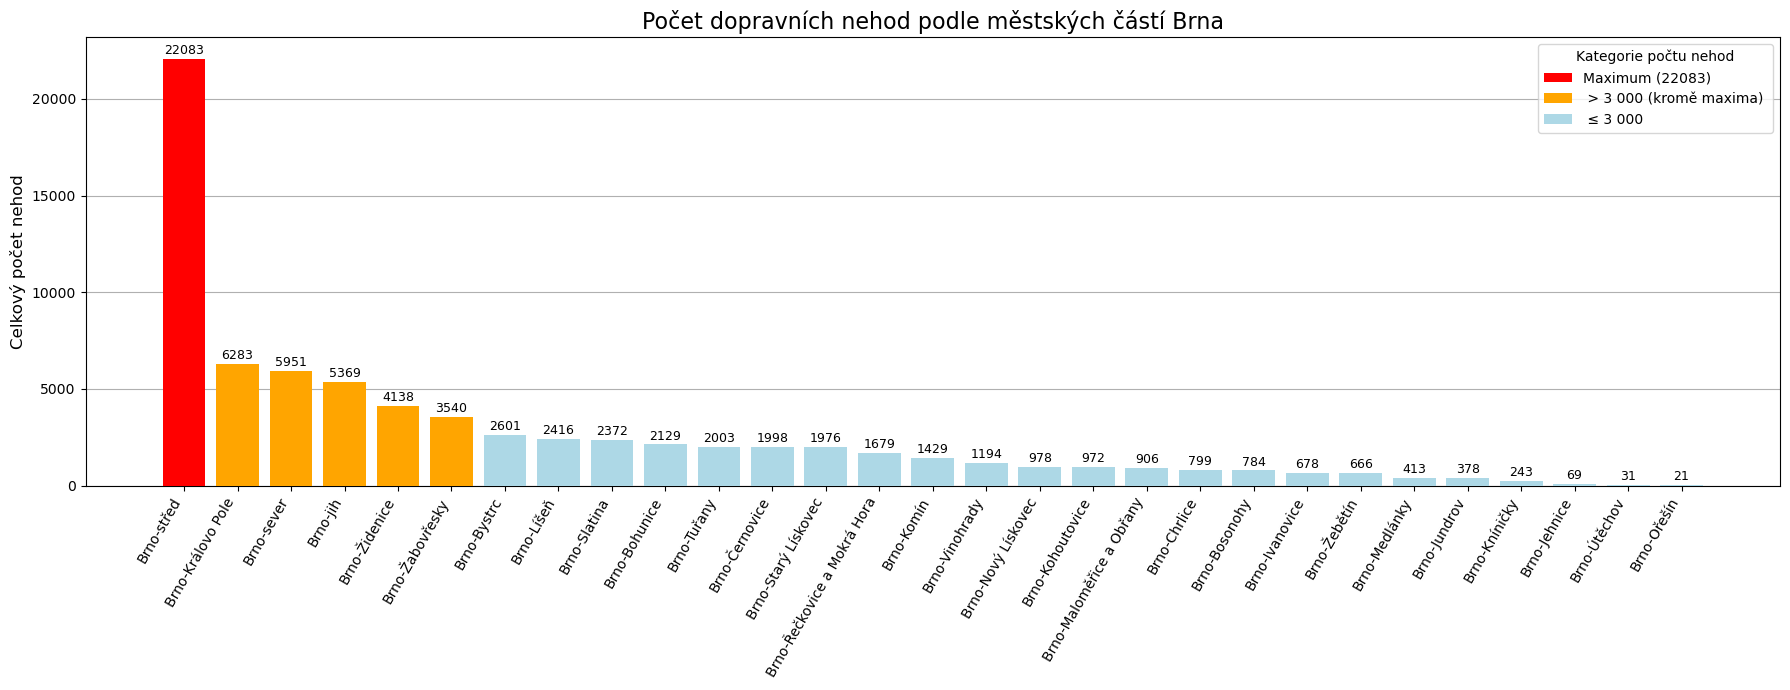

In [17]:
# Počet dopravních nehod podle městské části 
vsechny_mestske_casti = data['mestska_cast'].value_counts()

pocet_max = vsechny_mestske_casti.max()
limit = 3000

barvy_sloupcu = [
    'red' if pocet == pocet_max else      
    'orange' if pocet > limit else        
    'lightblue'                           
    for pocet in vsechny_mestske_casti.values
]

plt.figure(figsize=(18, 7))

pocettttttt = plt.bar(vsechny_mestske_casti.index, vsechny_mestske_casti.values, color=barvy_sloupcu)

ax = plt.gca()
ax.grid(axis='y', zorder=1)

for container in ax.containers:
    plt.setp(container, zorder=3)

for bar in pocettttttt:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2.0, 
        yval + 100, 
        int(yval), 
        ha='center', 
        va='bottom', 
        fontsize=9
    )

plt.title('Počet dopravních nehod podle městských částí Brna', fontsize=16)
plt.xlabel('', fontsize=12)
plt.ylabel('Celkový počet nehod', fontsize=12)


plt.xticks(rotation=60, ha='right')

legend_elements = [
    mpatches.Patch(facecolor='red', label=f'Maximum ({pocet_max})'),
    mpatches.Patch(facecolor='orange', label=' > 3 000 (kromě maxima) '),
    mpatches.Patch(facecolor='lightblue', label=' ≤ 3 000 ')
]

plt.legend(handles=legend_elements, loc='upper right', title="Kategorie počtu nehod", frameon=True)

plt.tight_layout()
plt.show()

### 3.10. Mapa - počet dopravních nehod podle městských částí Brna
- Mapa znázorňuje počet dopravních nehod v jednotlivých městských částech Brna.

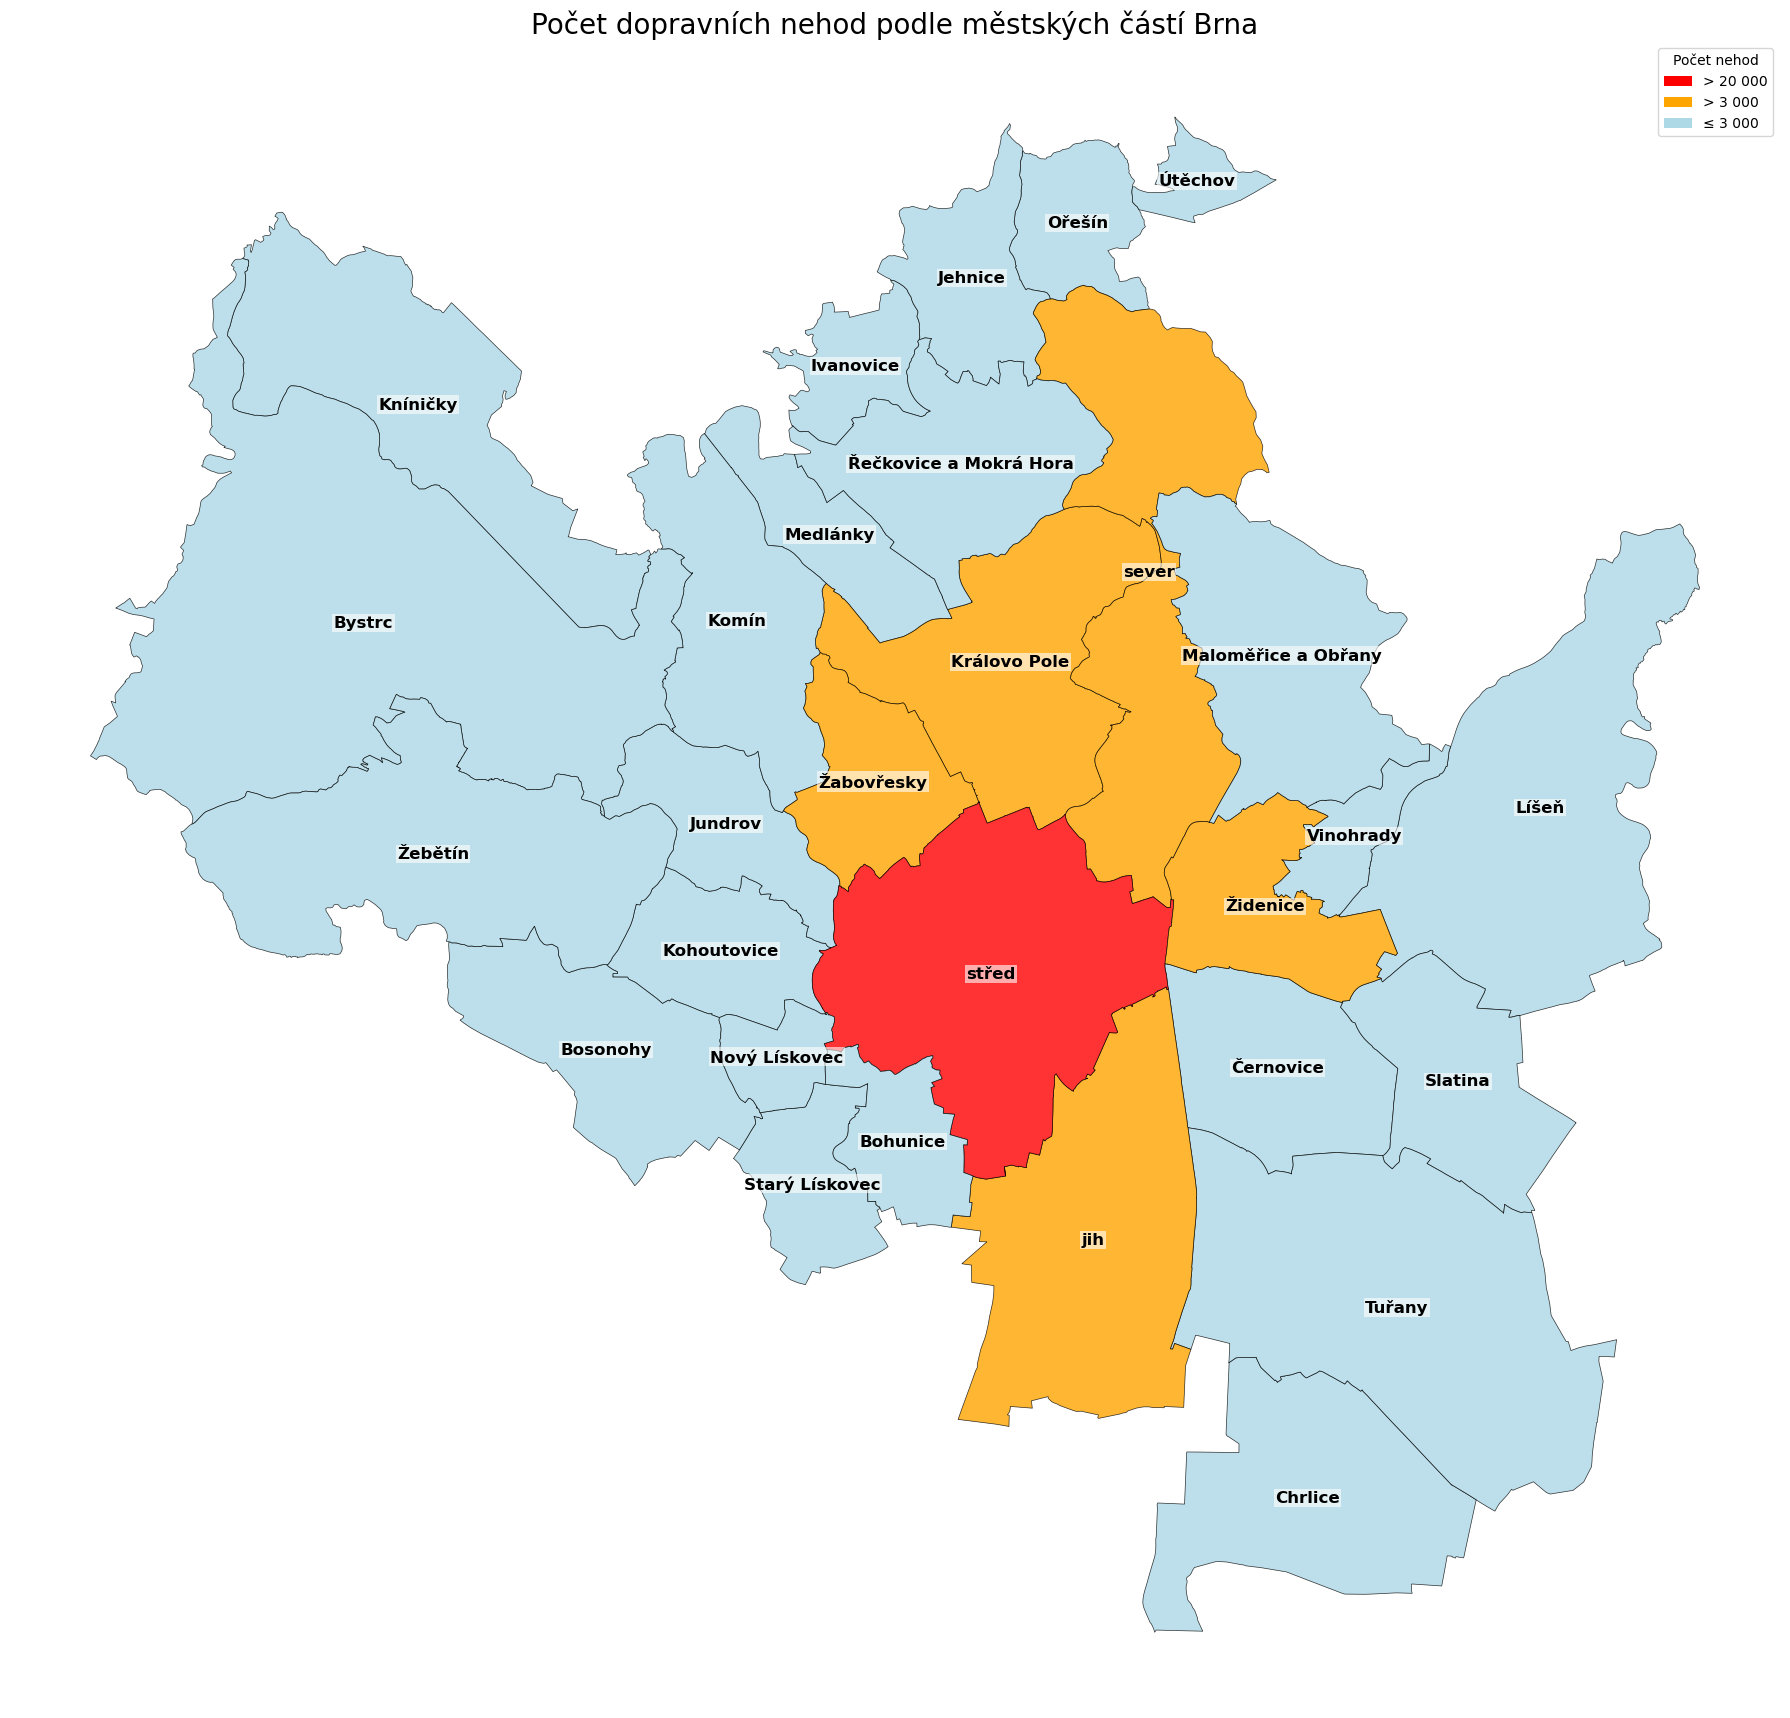

In [18]:
SLOUPEC_S_NAZVY = 'nazev' 

# Spočítání nehod
nehody_dle_mestske_casti = data['mestska_cast'].value_counts().reset_index()
nehody_dle_mestske_casti.columns = [SLOUPEC_S_NAZVY, 'pocet_nehod'] 

# Spojení GeoDataFrame s počty nehod
nehody_dle_mestske_casti = gdf_brno.merge(
    nehody_dle_mestske_casti,
    on=SLOUPEC_S_NAZVY,
    how='left'
).fillna({'pocet_nehod': 0}) 

maximum_nehod = nehody_dle_mestske_casti['pocet_nehod'].max()
limit = 3000 

def get_barva_nehod(pocet):
    pocet = int(pocet)
    # 1. Červená: Maximum
    if pocet == maximum_nehod and pocet > 0:
        return 'red'
    # 2. Oranžová: > 3000 (kromě maxima)
    elif pocet > limit:
        return 'orange'
    # 3. Světle modrá: <= 3000
    elif pocet > 0 and pocet <= limit: 
        return 'lightblue'

nehody_dle_mestske_casti['barva'] = nehody_dle_mestske_casti['pocet_nehod'].apply(get_barva_nehod)

fig, ax = plt.subplots(1, 1, figsize=(18, 18))

nehody_dle_mestske_casti.plot(
    ax=ax,
    color=nehody_dle_mestske_casti['barva'],
    edgecolor='black',
    linewidth=0.5,
    alpha=0.8
)

for idx, row in nehody_dle_mestske_casti.iterrows():
    centroid = row.geometry.centroid
    nazev_mc = row[SLOUPEC_S_NAZVY].replace('Brno-', '')
    
    ax.text(
        centroid.x, centroid.y, nazev_mc, 
        fontsize=12, ha='center', va='center', color='black', weight='bold', 
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=1)
    )

legend_elements = [
    mpatches.Patch(facecolor='red', label='> 20 000'),
    mpatches.Patch(facecolor='orange', label='> 3 000 '),
    mpatches.Patch(facecolor='lightblue', label='≤ 3 000')
]

ax.legend(handles=legend_elements, loc='upper right', title="Počet nehod")

plt.title('Počet dopravních nehod podle městských částí Brna', fontsize=20)
ax.set_axis_off() 
plt.tight_layout()
plt.show()

### 3.11. Mapa - dopravní nehody v kontextu počtu obyvatel
- Mapa znázorňuje vztah mezi počtem obyvatel jednotlivých městských částí a četností dopravních nehod.
- Barevné rozlišení označuje velikost populace a symboly vyjadřují počet nehod.

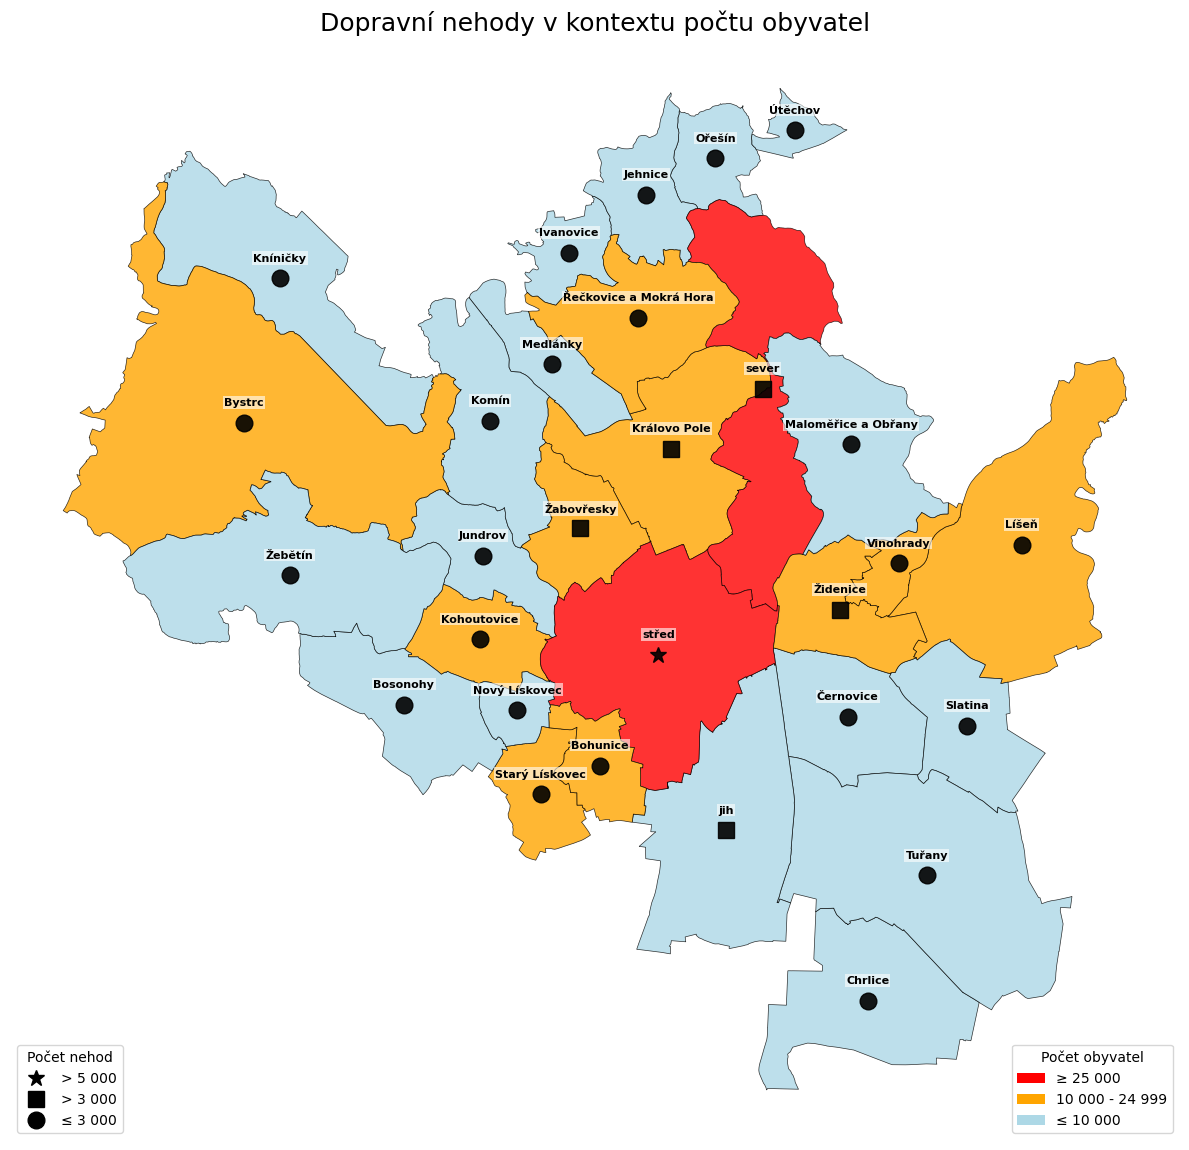

In [19]:
SLOUPEC_S_NAZVY = 'nazev'

Y_OFFSET = -800
SYMBOL_SIZE = 12
BARVA_NIZKA = 'lightblue'
BARVA_STREDNI = 'orange'
BARVA_VYSOKA = '#red'
BARVA_MAXIMUM = 'red'
BARVA_NULA_CHYBI = 'lightgray'

PRUH_NEHOD = 3000 
PRUH_OBYV_NIZKY = 10000
PRUH_OBYV_VYSOKY = 25000

nehody_dle_mestske_casti = data['mestska_cast'].value_counts().reset_index()
nehody_dle_mestske_casti.columns = [SLOUPEC_S_NAZVY, 'pocet_nehod']

# Přejmenování sloupce Mestska_cast v 'cast_obyv' na 'nazev' pro spojení
cast_obyv.rename(columns={'Mestska_cast': SLOUPEC_S_NAZVY}, inplace=True)
cast_obyv['pocet_obyvatel'] = cast_obyv['pocet_obyvatel'].astype(int)

# Spojení GeoDataFrame s oběma daty
gdf_final = gdf_brno.merge(cast_obyv, on=SLOUPEC_S_NAZVY, how='left')
gdf_final['pocet_obyvatel'] = gdf_final['pocet_obyvatel'].fillna(0)
gdf_final = gdf_final.merge(nehody_dle_mestske_casti, on=SLOUPEC_S_NAZVY, how='left')
gdf_final['pocet_nehod'] = gdf_final['pocet_nehod'].fillna(0)

def get_barva_obyvatel(pocet):
    # Horní skupina: ≥  25000
    if pocet >= PRUH_OBYV_VYSOKY: return BARVA_MAXIMUM 
    # Střední skupina: 10000 až < 25000
    elif pocet >= PRUH_OBYV_NIZKY: return BARVA_STREDNI 
    # Spodní skupina: < 10000 (včetně nuly)
    elif pocet >= 0: return BARVA_NIZKA
    else: return BARVA_NULA_CHYBI 

MAXIMUM_NEHOD = gdf_final['pocet_nehod'].max()

def get_marker_symbol(pocet):
    # Maximum nehod
    if pocet == MAXIMUM_NEHOD and pocet > 0: return '*' 
    # Nad novým prahem 1000
    elif pocet > PRUH_NEHOD: return 's' 
    # Ostatní (včetně nuly)
    else: return 'o'

gdf_final['barva_obyvatel'] = gdf_final['pocet_obyvatel'].apply(get_barva_obyvatel)
gdf_final['symbol_nehody'] = gdf_final['pocet_nehod'].apply(get_marker_symbol)

fig, ax = plt.subplots(1, 1, figsize=(12, 12))

gdf_final.plot(
    ax=ax,
    color=gdf_final['barva_obyvatel'],
    edgecolor='black',
    linewidth=0.5,
    alpha=0.8
)

for idx, row in gdf_final.iterrows():
    centroid = row.geometry.centroid
    
    # Kreslení symbolu nehody
    ax.plot(
        centroid.x,
        centroid.y,
        marker=row['symbol_nehody'], 
        color='black',
        markersize=SYMBOL_SIZE, 
        alpha=0.9
    )
    
    nazev_mc = row[SLOUPEC_S_NAZVY].replace('Brno-', '').replace('Brno–', '')
    pocet_nehod = int(row['pocet_nehod'])

    text = f"{nazev_mc}" 
    
    ax.text(
        centroid.x,
        centroid.y - Y_OFFSET, 
        text, 
        fontsize=8,
        ha='center',
        va='top', 
        color='black',
        weight='bold',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=1)
    )

# Legenda pro BARVY (Obyvatelé)
legend_barva = [
    plt.Rectangle((0, 0), 1, 1, fc=BARVA_MAXIMUM, label=f'≥ 25 000'),  
    plt.Rectangle((0, 0), 1, 1, fc=BARVA_STREDNI, label=f'10 000 - 24 999' ), 
    plt.Rectangle((0, 0), 1, 1, fc=BARVA_NIZKA, label=f'≤ 10 000')   
]

# Legenda pro SYMBOLY (Nehody)
legend_symbol = [
    plt.plot([], [], marker='*', color='black', markersize=SYMBOL_SIZE, linestyle='None', label=f'> 5 000')[0],
    plt.plot([], [], marker='s', color='black', markersize=SYMBOL_SIZE, linestyle='None', label=f'> 3 000')[0],
    plt.plot([], [], marker='o', color='black', markersize=SYMBOL_SIZE, linestyle='None', label=f'≤ 3 000')[0],
]

legend1 = ax.legend(handles=legend_barva, loc='lower right', title="Počet obyvatel")
ax.add_artist(legend1)
ax.legend(handles=legend_symbol, loc='lower left', title="Počet nehod")

plt.title('Dopravní nehody v kontextu počtu obyvatel', fontsize=18)
ax.set_axis_off() 
plt.tight_layout()
plt.show()

### 3.12. Filtrace dopravních nehod podle roku
- Pole „CILOVY_ROK“ slouží k zadání roku, podle kterého se data filtrují

In [20]:
spravny_format = '%m/%d/%Y %I:%M:%S %p' 
data['datum'] = pd.to_datetime(data['datum'], format=spravny_format, errors='coerce')

CILOVY_ROK = 2023 

maska_roku = data['datum'].dt.year == CILOVY_ROK
data_rok = data[maska_roku].copy()

pocet_nehod_v_roce = len(data_rok)
if pocet_nehod_v_roce > 0:
    print(f"Data úspěšně filtrována. Počet nehod v roce {CILOVY_ROK}: {pocet_nehod_v_roce}")
else:
    print(f"Varování: V roce {CILOVY_ROK} nebyly nalezeny žádné nehody nebo se nepodařilo převést datum.")

Data úspěšně filtrována. Počet nehod v roce 2023: 4243


### 3.13. Interaktivní mapa - Srážky s chodci v městské části Brno‑střed
- Interaktivní mapa zobrazuje prostorové rozložení intenzity sražky s chodci pomocí heatmapy.

In [21]:
mask_stred = data.iloc[:, 1].str.contains('Brno-střed', na=False)
mask_chodci = data['srazka'].str.contains('srážka s chodcem', na=False, case=False)

data_filtr = data[mask_stred & mask_chodci].copy()

x = pd.to_numeric(data_filtr.iloc[:, -2], errors='coerce')
y = pd.to_numeric(data_filtr.iloc[:, -1], errors='coerce')

geometry = [Point(xy) for xy in zip(x, y)]
# Je to v S–JTSK (5514)
valid_gdf = gpd.GeoDataFrame(data_filtr, geometry=geometry, crs="EPSG:5514")

# Převod na stupně pro Folium (nezbytné pro zobrazení) – WGS (4326)
valid = valid_gdf.dropna(subset=['geometry']).to_crs(epsg=4326)

if not valid.empty:
    m = folium.Map(
        location=[valid.geometry.y.mean(), valid.geometry.x.mean()],
        zoom_start=15, 
        tiles="CartoDB Positron"
    )
    
    # Heatmapa intenzity srážek s chodci
    heat_data = [[row.geometry.y, row.geometry.x, 1] for idx, row in valid.iterrows()]
    plugins.HeatMap(heat_data, radius=25, blur=15).add_to(m)
    
    # Marker Cluster pro jednotlivé nehody
    marker_cluster = plugins.MarkerCluster().add_to(m)
    
    for idx, row in valid.iterrows():
        text_html = f"""
        <b>ID:</b> {row.get('OBJECTID', 'N/A')}<br>
        <b>Příčina:</b> {row.get('hlavni_pricina', 'N/A')}<br>
        <b>Následky:</b> {row.get('nasledky', 'N/A')}
        """
        
        folium.Marker(
            location=[row.geometry.y, row.geometry.x],
            popup=folium.Popup(text_html, max_width=250),
            icon=folium.Icon(color="orange", icon="walking", prefix="fa")
        ).add_to(marker_cluster)
        
    display(m)
    print(f"Zobrazeno {len(valid)} srážek s chodcem v městské části Brno-střed.")
else:
    print("Pro zadané filtry nebyla nalezena žádná data.")

Zobrazeno 2254 srážek s chodcem v městské části Brno-střed.


### 3.14. Interaktivní graf - Celková hmotná škoda v jednotlivých měsících
- Graf znázorňuje celkovou výši částky v jednotlivých měsících.
- Použitá knihovna plotly.graph_objects.

In [22]:
warnings.filterwarnings("ignore", category=FutureWarning)# Potlačení varování

# Příprava dat
data['datum'] = pd.to_datetime(data['datum'])
data['rok_mesic'] = data['datum'].dt.to_period('M')
monthly_damage = data.groupby('rok_mesic')['hmotna_skoda'].sum().reset_index()
monthly_damage['rok_mesic_dt'] = monthly_damage['rok_mesic'].dt.to_timestamp()

# Mapa měsíců do češtiny
czech_months = {
    1: 'leden', 2: 'únor', 3: 'březen', 4: 'duben', 5: 'květen', 6: 'červen',
    7: 'červenec', 8: 'srpen', 9: 'září', 10: 'říjen', 11: 'listopad', 12: 'prosinec'
}

# Pomocné sloupce pro bublinu
monthly_damage['Rok'] = monthly_damage['rok_mesic_dt'].dt.year
monthly_damage['Mesic_Nazev'] = monthly_damage['rok_mesic_dt'].dt.month.map(czech_months)
monthly_damage['Castka_Format'] = monthly_damage['hmotna_skoda'].apply(lambda x: f"{x:,.0f} CZK".replace(",", " "))

# 3. Barevná logika
top_3_threshold = monthly_damage['hmotna_skoda'].nlargest(3).min()

def get_category(val):
    if val >= top_3_threshold: return 'Top 3 nejvyšší'
    if val > 50000000: return 'Nad 50M CZK'
    return 'Pod 50M CZK'

monthly_damage['Kategorie'] = monthly_damage['hmotna_skoda'].apply(get_category)

color_map = {'Top 3 nejvyšší': 'red', 'Nad 50M CZK': 'orange', 'Pod 50M CZK': 'lightblue'}

# Tvorba grafu
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=monthly_damage['rok_mesic_dt'].tolist(),
    y=monthly_damage['hmotna_skoda'].tolist(),
    mode='lines',
    line=dict(color='lightgray', width=2),
    hoverinfo='skip',
    showlegend=False
))

# Barevné body
for kat, color in color_map.items():
    subset = monthly_damage[monthly_damage['Kategorie'] == kat]
    fig.add_trace(go.Scatter(
        x=subset['rok_mesic_dt'].tolist(),
        y=subset['hmotna_skoda'].tolist(),
        mode='markers',
        name=kat,
        marker=dict(color=color, size=10, line=dict(width=1, color='DarkSlateGrey')),
        customdata=subset[['Mesic_Nazev', 'Rok', 'Castka_Format']],
        hovertemplate="<b>%{customdata[0]} %{customdata[1]}</b><br>" +
                      "Škoda: %{customdata[2]}<extra></extra>"
    ))

fig.update_layout(
    title='Celková hmotná škoda v jednotlivých měsících (Interaktivní)',
    xaxis_title='Datum',
    yaxis_title='Hmotná Škoda (CZK)',
    legend_title='Kategorie',
    template='plotly_white',
    hovermode='closest'
)

fig.show()

# statistiky
mean_skoda = data['hmotna_skoda'].mean()
median_skoda = data['hmotna_skoda'].median()
total_skoda = data['hmotna_skoda'].sum()
unique_years_sorted = sorted(data['rok'].unique())

print("--- Roky obsažené v datech ---")
print(unique_years_sorted)
print(f"\n--- Statistické shrnutí Hmotné Škody ---")
print(f"Průměrná hmotná škoda na nehodu: {mean_skoda:,.2f} CZK")
print(f"Medián hmotné škody na nehodu: {median_skoda:,.2f} CZK")
print(f"Celková hmotná škoda: {total_skoda:,.2f} CZK")

--- Roky obsažené v datech ---
[2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]

--- Statistické shrnutí Hmotné Škody ---
Průměrná hmotná škoda na nehodu: 68,562.79 CZK
Medián hmotné škody na nehodu: 21,000.00 CZK
Celková hmotná škoda: 5,080,434,200.00 CZK


### 3.15 Analýza prostorových rizik kolem škol a školek v okruhu 200 metrů
- Nepodařilo se zprovoznit, pravděpodobně z přepisování načítání dat. Nezbyl čas.
- Načte nehody, ale počet nehod je 0.

In [34]:
# 1. Definice konstant (Musí být v této buňce nebo spuštěné dříve)
METRICKY_CRS = "EPSG:5514"  # Systém S-JTSK používaný v ČR
BUFFER_METRY = 200

# 2. Funkce pro vytvoření sloučeného bufferu
def create_dissolved_buffer_from_gdf(gdf, buffer_size, target_crs):
    """Převede GDF na metrický CRS, vytvoří buffer a sloučí jej do jednoho celku."""
    # Převod na metrický CRS (JTSK) pro přesný výpočet v metrech
    gdf_metric = gdf.to_crs(target_crs)
    
    # Vytvoření bufferu
    gdf_buffer = gdf_metric.buffer(buffer_size) 
    
    # Sloučení všech polygonů do jednoho (pro rychlejší výpočet sjoin)
    slouceny_polygon = gdf_buffer.unary_union 
    
    return gpd.GeoDataFrame(geometry=[slouceny_polygon], crs=target_crs)

# 3. Tvorba bodů nehod (použije původní 'data' z tvého načítání)
# Odstraníme řádky bez souřadnic a vytvoříme geometrii
data_nehody = data.dropna(subset=['x', 'y']).copy() 
data_nehody['geometry'] = [Point(xy) for xy in zip(data_nehody['x'], data_nehody['y'])]
gdf_nehody = gpd.GeoDataFrame(data_nehody, geometry='geometry', crs=METRICKY_CRS)

# 4. Tvorba rizikových zón (opraveno na názvy ZIP_SKOLY/ZIP_SKOLKY z tvého stahování)
buffer_skoly = create_dissolved_buffer_from_gdf(ZIP_SKOLY, BUFFER_METRY, METRICKY_CRS)
buffer_skolky = create_dissolved_buffer_from_gdf(ZIP_SKOLKY, BUFFER_METRY, METRICKY_CRS)

# 5. Sjednocení obou zón do jedné finální
# Použijeme .union() pro spojení dvou polygonů
sjednocena_geometrie = buffer_skoly.geometry.iloc[0].union(buffer_skolky.geometry.iloc[0])
final_rizikova_zona = gpd.GeoDataFrame(geometry=[sjednocena_geometrie], crs=METRICKY_CRS)

# 6. Prostorové spojení (zjištění nehod uvnitř zóny)
nehody_v_zone = gpd.sjoin(gdf_nehody, final_rizikova_zona, how='inner', predicate='within')

# 7. Výpis výsledků
print("\n--- VÝSLEDKY ANALÝZY PROSTOROVÉHO RIZIKA ---")
print(f"Celkový počet nehod analyzovaných: {len(gdf_nehody)}")
print(f"Počet nehod, které se staly do {BUFFER_METRY} metrů od škol/školek: {len(nehody_v_zone)}")

if len(gdf_nehody) > 0:
    procento_v_zone = (len(nehody_v_zone) / len(gdf_nehody)) * 100
    print(f"Podíl nehod v rizikové zóně: {procento_v_zone:.2f}%")


--- VÝSLEDKY ANALÝZY PROSTOROVÉHO RIZIKA ---
Celkový počet nehod analyzovaných: 74099
Počet nehod, které se staly do 200 metrů od škol/školek: 0
Podíl nehod v rizikové zóně: 0.00%


/tmp/ipykernel_1472181/2638944677.py:15: DeprecationWarning:

The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.

/tmp/ipykernel_1472181/2638944677.py:15: DeprecationWarning:

The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.



### 3.16 Vytvoření souboru requirements.txt
- Na závěr byl vytvořen soubor požadavků, který obsahuje seznam všech knihoven a jejich verzí použitých v projektu. 
- Tento soubor slouží k zajištění plné kompatibility a snadné replikaci vývojového prostředí na jiných zařízeních.

In [36]:
!pip freeze > requirements.txt
print("Soubor requirements.txt byl úspěšně vytvořen")

Soubor requirements.txt byl úspěšně vytvořen


# **ZÁVĚR** 
- V rámci zpracování této analýzy jsme se soustředili na zhodnocení dopravní nehodovosti v Brně, přičemž se nám podařilo úspěšně naplnit stanovené cíle. 
- Skrze hloubkové zpracování dat jsme identifikovali klíčové rizikové faktory a lokality, zejména v centru města a na hlavních dopravních uzlech, kde se jako rozhodující prvek opakovaně ukázalo lidské pochybení v podobě nesprávného způsobu jízdy či nedání přednosti. 
- Výsledné interaktivní vizualizace představují funkční výstup, který potvrzuje naše předpoklady o prostorové distribuci nehod a nabízí ucelený odborný pohled na bezpečnost silničního provozu v celém městském prostoru.

**ČVUT FSv – UZPR**

**Zpracovali: Hnízdilová E. a Zeman V.**

**prosinec 2025, V Praze**